Project Title: Maternal satisfaction among vaginal and cesarean section delivery care services in Bahir Dar city health facilities, Northwest Ethiopia:

Objective: Analyze maternal satisfaction data using descriptive statistics and machine learning (Logistic Regression) to identify key factors and build a predictive model. The dependent variable is 'satisfaction' (dummy variable).



***first import the main pyton libraries***

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import scipy.stats as stats

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
!pip install pyreadstat ###  installing this package and used as a library in orderto read spss files in Python.

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.9/2.9 MB 25.9 MB/s  0:00:00


In [4]:
import pandas as pd

# Load the .sav file into a pandas DataFrame
# The filename has been corrected based on available files in Google Drive.
df = pd.read_spss('/content/drive/MyDrive/Delivery care satisfaction.sav') # Corrected filename

# Display the first 5 rows of the DataFrame
display(df.head())

,q101age,q102mstatu,q103religi,q104ethini,q105educat,q106occupa,q107mincom,q108reside,q1091distk,q1092disth,...,encourageandsupportatdeliveryrecode,politenessrecode,availabilityofmedicalequipmentsrecode,counselingrecode,overallcleanessrecode,accessandcleanessoftoiletrecode,waitingareacleanessandconfort,availabilityofbedintheward,distancerecode1,wolkingdistancerecodeinhrs
0,22.0,married,orthodox,amhara,grade 5 to 8,others,800.0,rural,0.0,200.0,...,not satisfied,not satisfied,not satisfied,not satisfied,not satisfied,not satisfied,not satisfied,not satisfied,<=10 kilo meters,>2 hrs
1,35.0,married,orthodox,tigrie,grade 5 to 8,merchants,7000.0,urban,0.0,50.0,...,satisfied,satisfied,satisfied,satisfied,satisfied,satisfied,satisfied,satisfied,<=10 kilo meters,>2 hrs
2,20.0,married,orthodox,amhara,grade 9 to 10,merchants,1500.0,urban,5.0,NaN,...,satisfied,satisfied,satisfied,satisfied,satisfied,satisfied,satisfied,satisfied,<=10 kilo meters,NaN
3,26.0,married,orthodox,amhara,grade 1 to 4,huose wife,900.0,urban,0.0,11.0,...,satisfied,satisfied,satisfied,satisfied,satisfied,satisfied,satisfied,satisfied,<=10 kilo meters,>2 hrs
4,22.0,married,muslim,amhara,grade 11 to 12,students,1536.0,rural,5.0,NaN,...,satisfied,satisfied,satisfied,satisfied,satisfied,satisfied,satisfied,satisfied,<=10 kilo meters,NaN


### Part 1: Descriptive Analysis

In [5]:
# Display general information about the DataFrame, including data types and non-null values
print('DataFrame Info:')
df.info()

# Display descriptive statistics for numerical columns
print('\nDescriptive Statistics for Numerical Columns:')
display(df.describe())

DataFrame Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 894 entries, 0 to 893
Data columns (total 46 columns):
 #   Column                                 Non-Null Count  Dtype   
---  ------                                 --------------  -----   
 0   q101age                                894 non-null    float64 
 1   q102mstatu                             894 non-null    category
 2   q103religi                             894 non-null    category
 3   q104ethini                             894 non-null    category
 4   q105educat                             894 non-null    category
 5   q106occupa                             894 non-null    category
 6   q107mincom                             894 non-null    float64 
 7   q108reside                             894 non-null    category
 8   q1091distk                             894 non-null    float64 
 9   q1092disth                             320 non-null    float64 
 10  q110reason                             894 non

,q101age,q107mincom,q1091distk,q1092disth,q205ga,q2010bw
count,894.000000,894.000000,894.000000,320.000000,894.000000,894.000000
mean,26.602908,4096.879195,19.286353,16.671875,39.395973,2941.728188
std,4.881351,4470.313904,44.228470,16.815293,1.550864,540.414864
min,17.000000,200.000000,0.000000,1.000000,32.000000,1111.000000
25%,23.000000,1537.750000,0.000000,4.000000,39.000000,2600.000000
50%,27.000000,3000.000000,5.000000,12.000000,39.000000,2900.000000
75%,30.000000,5300.000000,15.000000,30.000000,40.000000,3200.000000
max,42.000000,50000.000000,500.000000,200.000000,43.000000,5001.000000


In [6]:
# Display descriptive statistics for categorical columns
print('Descriptive Statistics for Categorical Columns:')
display(df.describe(include='category'))

# Display value counts for the 'satisfaction' column
print('\nValue Counts for Dependent Variable (satisfaction):')
display(df['satisfaction'].value_counts())

Descriptive Statistics for Categorical Columns:


,q102mstatu,q103religi,q104ethini,q105educat,q106occupa,q108reside,q110reason,q111timeta,q112waitpl,q113privac,...,encourageandsupportatdeliveryrecode,politenessrecode,availabilityofmedicalequipmentsrecode,counselingrecode,overallcleanessrecode,accessandcleanessoftoiletrecode,waitingareacleanessandconfort,availabilityofbedintheward,distancerecode1,wolkingdistancerecodeinhrs
count,894,894,894,894,894,894,894,894,894,894,...,894,894,894,894,894,894,894,894,894,275
unique,5,4,4,7,6,2,2,2,2,2,...,2,2,2,2,2,2,2,2,2,1
top,married,orthodox,amhara,diploma and above,huose wife,urban,planed,<1hr,yes,yes,...,satisfied,satisfied,satisfied,satisfied,satisfied,satisfied,satisfied,satisfied,<=10 kilo meters,>2 hrs
freq,712,608,715,321,288,690,496,706,595,695,...,719,711,696,676,591,506,561,545,652,275



Value Counts for Dependent Variable (satisfaction):


,count
satisfaction,
satisfied,549
not satisfied,345


In [7]:
# Identify categorical columns for frequency analysis
categorical_cols = df.select_dtypes(include='category').columns

print('\nFrequency Counts for Categorical Columns:')
for col in categorical_cols:
    print(f'\n--- {col} ---')
    display(df[col].value_counts())
    print(f'Missing values in {col}: {df[col].isnull().sum()}')


Frequency Counts for Categorical Columns:

--- q102mstatu ---


,count
q102mstatu,
married,712
single,98
cohabited,67
widowed,10
divorced,7


Missing values in q102mstatu: 0

--- q103religi ---


,count
q103religi,
orthodox,608
muslim,193
protestant,88
88.0,5


Missing values in q103religi: 0

--- q104ethini ---


...

Missing values in availabilityofbedintheward: 0

--- distancerecode1 ---


,count
distancerecode1,
<=10 kilo meters,652
>10 kilo meters,242


Missing values in distancerecode1: 0

--- wolkingdistancerecodeinhrs ---


,count
wolkingdistancerecodeinhrs,
>2 hrs,275


Missing values in wolkingdistancerecodeinhrs: 619


In [8]:
# Calculate and display variance for numerical columns
print('\nVariance for Numerical Columns:')
numerical_cols = df.select_dtypes(include=['float64', 'int64']).columns
display(df[numerical_cols].var())


Variance for Numerical Columns:


,0
q101age,2.382758e+01
q107mincom,1.998371e+07
q1091distk,1.956158e+03
q1092disth,2.827541e+02
q205ga,2.405180e+00
q2010bw,2.920482e+05


### Visualizing Distributions of Variables

Histograms for Numerical Features:


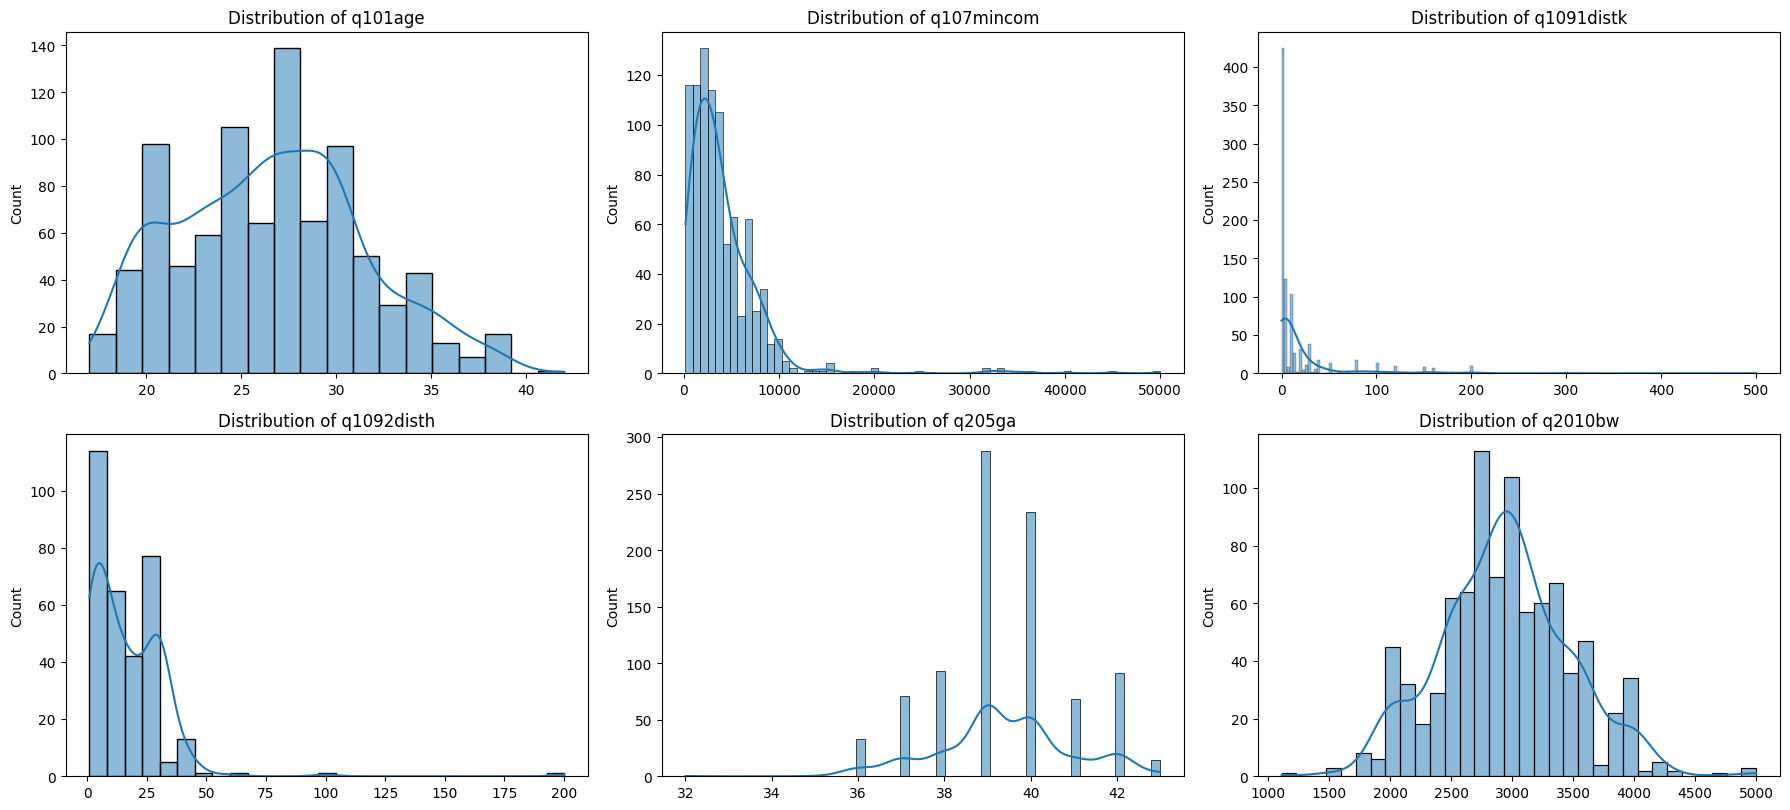

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns
# Visualize distributions of numerical columns
print('Histograms for Numerical Features:')
numerical_cols = df.select_dtypes(include=['float64', 'int64']).columns

plt.figure(figsize=(18, 12))
for i, col in enumerate(numerical_cols):
    plt.subplot(3, 3, i + 1) # Adjust subplot grid as needed
    sns.histplot(df[col].dropna(), kde=True)
    plt.title(f'Distribution of {col}')
    plt.xlabel('')
plt.tight_layout()
plt.show()


Bar Plots for Categorical Features (Top 10):


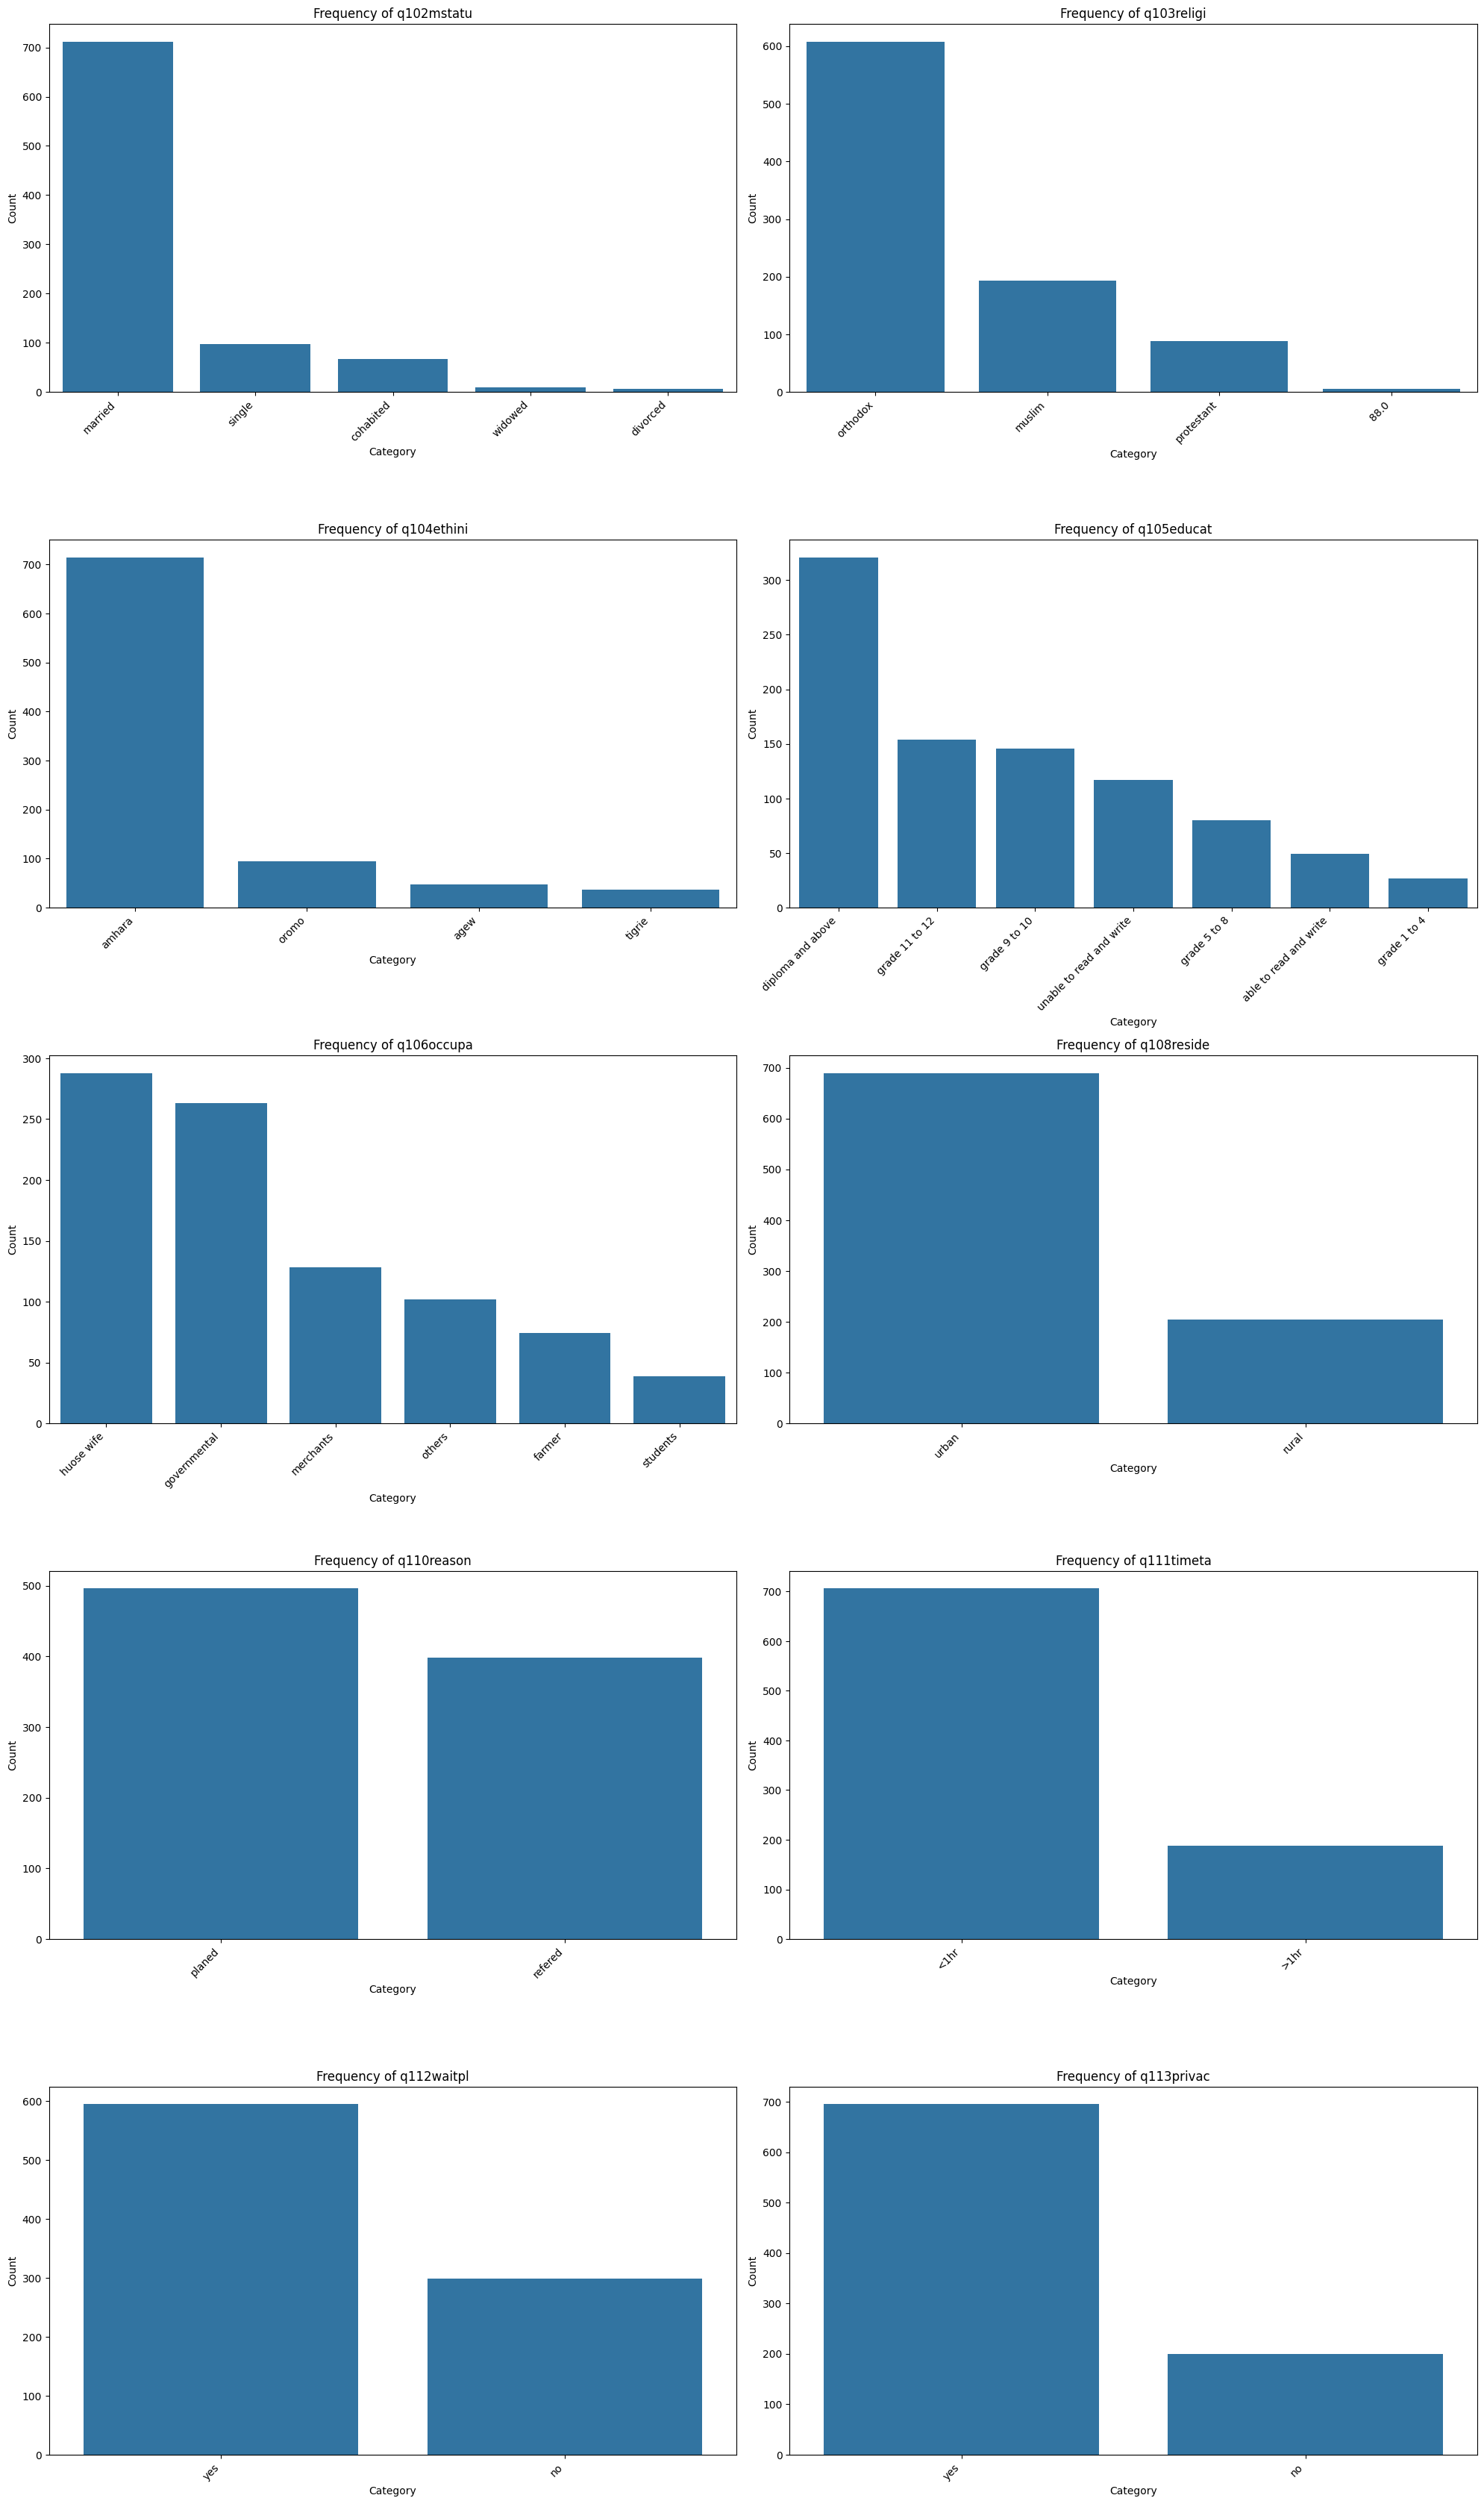

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns
# Visualize distributions of categorical columns (top 10 for readability)
print('\nBar Plots for Categorical Features (Top 10):')
categorical_cols = df.select_dtypes(include='category').columns

# Exclude 'satisfaction' for now as we'll analyze it specifically later
categorical_cols = [col for col in categorical_cols if col != 'satisfaction']

# Limit to a reasonable number of plots for display, e.g., first 10 categorical columns
num_plots = min(10, len(categorical_cols))
plt.figure(figsize=(20, num_plots * 4))

for i, col in enumerate(categorical_cols[:num_plots]):
    plt.subplot(num_plots // 2 + 1, 2, i + 1) # Adjust subplot grid
    sns.countplot(data=df, x=col, order=df[col].value_counts().index) # Changed y=col to x=col for vertical bars
    plt.title(f'Frequency of {col}')
    plt.xlabel('Category') # Adjusted x-label
    plt.ylabel('Count') # Adjusted y-label
    plt.xticks(rotation=45, ha='right') # Rotate x-axis labels for readability
plt.tight_layout()
plt.show()


Distribution of Target Variable (Satisfaction):


/tmp/ipykernel_2847/242698609.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='satisfaction', palette='viridis')


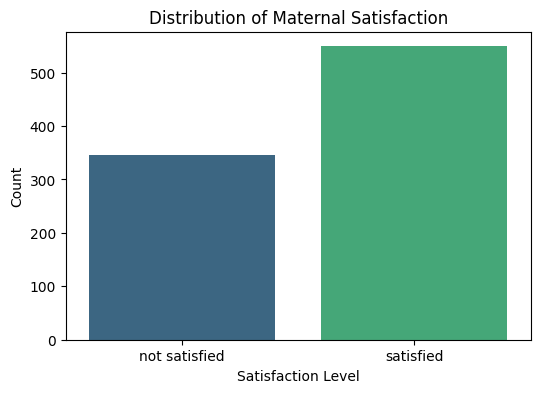

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns
# Visualize the distribution of the target variable 'satisfaction'
print('\nDistribution of Target Variable (Satisfaction):')
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='satisfaction', palette='viridis')
plt.title('Distribution of Maternal Satisfaction')
plt.xlabel('Satisfaction Level')
plt.ylabel('Count')
plt.show()


Maternal Satisfaction by Mode of Delivery:


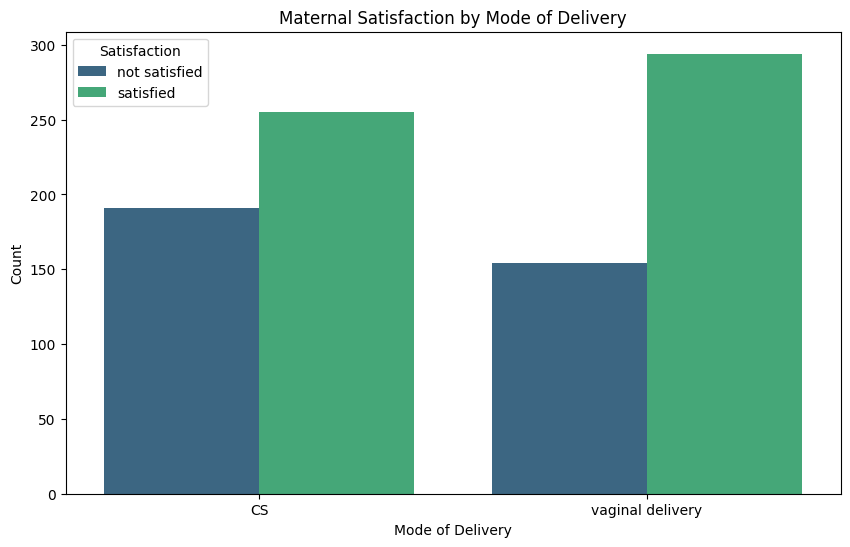

In [12]:
# Analyze maternal satisfaction by mode of delivery
print('\nMaternal Satisfaction by Mode of Delivery:')

plt.figure(figsize=(10, 6))
sns.countplot(data=df, x='modeofdeliveryrecode', hue='satisfaction', palette='viridis')
plt.title('Maternal Satisfaction by Mode of Delivery')
plt.xlabel('Mode of Delivery')
plt.ylabel('Count')
plt.legend(title='Satisfaction')
plt.show()

### Part 2: Feature Engineering and Data Management

In [13]:
# Step 1: Handling Missing Values

# Identify columns with missing values
missing_cols = df.columns[df.isnull().any()].tolist()

print("Columns with missing values:", missing_cols)

# Calculate and display the percentage of missing values for identified columns
missing_percentages = df[missing_cols].isnull().sum() * 100 / len(df)
print("\nPercentage of missing values per column:")
display(missing_percentages.sort_values(ascending=False))

Columns with missing values: ['q1092disth', 'wolkingdistancerecodeinhrs']

Percentage of missing values per column:


,0
wolkingdistancerecodeinhrs,69.239374
q1092disth,64.205817


In [14]:
# Drop columns with high percentage of missing values
columns_to_drop = ['q1092disth', 'wolkingdistancerecodeinhrs']
df = df.drop(columns=columns_to_drop)

print(f"Columns dropped: {columns_to_drop}")
print("DataFrame shape after dropping columns:", df.shape)

Columns dropped: ['q1092disth', 'wolkingdistancerecodeinhrs']
DataFrame shape after dropping columns: (894, 44)


### Step 2: Feature Encoding (Categorical Variables)

Now that we've handled missing values, the next step is to convert our categorical features into a numerical format that machine learning models can understand. We will use appropriate encoding techniques, such as One-Hot Encoding for nominal variables and Label Encoding for ordinal variables, if any.

Let's first identify which categorical columns need encoding, excluding our target variable `satisfaction` for now.

In [15]:
# Identify categorical columns for encoding (excluding the target variable)
categorical_features_for_encoding = df.select_dtypes(include='category').columns.tolist()
if 'satisfaction' in categorical_features_for_encoding:
    categorical_features_for_encoding.remove('satisfaction')

print("Categorical features to be encoded:", categorical_features_for_encoding)
print("Number of categorical features to be encoded:", len(categorical_features_for_encoding))

Categorical features to be encoded: ['q102mstatu', 'q103religi', 'q104ethini', 'q105educat', 'q106occupa', 'q108reside', 'q110reason', 'q111timeta', 'q112waitpl', 'q113privac', 'q201parity', 'q202cpplan', 'q203ancatt', 'q204hivres', 'q206delimo', 'q207nstatu', 'q208pdhsta', 'q209nsex', 'q301greeti', 'q302respec', 'q303delive', 'q411owners', 'ageafterrecod', 'monthlyincomerecode', 'gestationaagerecode', 'birthweightofbaby', 'modeofdeliveryrecode', 'waitingtimerecode', 'privacyrecode', 'encourageandsupportatdeliveryrecode', 'politenessrecode', 'availabilityofmedicalequipmentsrecode', 'counselingrecode', 'overallcleanessrecode', 'accessandcleanessoftoiletrecode', 'waitingareacleanessandconfort', 'availabilityofbedintheward', 'distancerecode1']
Number of categorical features to be encoded: 38


In [16]:
# Apply One-Hot Encoding to categorical features
df_encoded = pd.get_dummies(df, columns=categorical_features_for_encoding, drop_first=True)

print("DataFrame shape after One-Hot Encoding:", df_encoded.shape)
print("First 5 rows of the encoded DataFrame:")
display(df_encoded.head())

DataFrame shape after One-Hot Encoding: (894, 68)
First 5 rows of the encoded DataFrame:


,q101age,q107mincom,q1091distk,q205ga,q2010bw,satisfaction,q102mstatu_divorced,q102mstatu_married,q102mstatu_single,q102mstatu_widowed,...,privacyrecode_satisfied,encourageandsupportatdeliveryrecode_satisfied,politenessrecode_satisfied,availabilityofmedicalequipmentsrecode_satisfied,counselingrecode_satisfied,overallcleanessrecode_satisfied,accessandcleanessoftoiletrecode_satisfied,waitingareacleanessandconfort_satisfied,availabilityofbedintheward_satisfied,distancerecode1_>10 kilo meters
0,22.0,800.0,0.0,41.0,1111.0,not satisfied,False,True,False,False,...,False,False,False,False,False,False,False,False,False,False
1,35.0,7000.0,0.0,41.0,3000.0,satisfied,False,True,False,False,...,True,True,True,True,True,True,True,True,True,False
2,20.0,1500.0,5.0,42.0,3000.0,satisfied,False,True,False,False,...,True,True,True,True,True,True,True,True,True,False
3,26.0,900.0,0.0,39.0,2600.0,satisfied,False,True,False,False,...,True,True,True,True,True,True,True,True,True,False
4,22.0,1536.0,5.0,39.0,2800.0,satisfied,False,True,False,False,...,True,True,True,True,True,True,True,True,True,False


### Step 3: Feature Scaling (Numerical Variables)

Now that we have handled missing values and encoded categorical variables, the next step is to scale our numerical features. Many machine learning algorithms perform better when numerical input variables are scaled to a standard range. We will use `StandardScaler` to standardize the numerical features (mean=0, variance=1).

In [17]:
from sklearn.preprocessing import StandardScaler

# Identify numerical columns (excluding the target variable)
numerical_cols_for_scaling = df_encoded.select_dtypes(include=['float64', 'int64']).columns.tolist()

if 'satisfaction' in numerical_cols_for_scaling:
    numerical_cols_for_scaling.remove('satisfaction')

print("Numerical features identified for scaling after split:", numerical_cols_for_scaling)

# Create df_scaled as a clean copy of our encoded features.
# The actual fit and transformation will now be done safely after the train-test split.
df_scaled = df_encoded.copy()

Numerical features identified for scaling after split: ['q101age', 'q107mincom', 'q1091distk', 'q205ga', 'q2010bw']


### Part 3: Model Training

#### Step 1: Data Splitting (Train-Test Split)

Before training any model, it's crucial to split our processed dataset into training and testing sets. The training set will be used to train the machine learning model, and the testing set will be used to evaluate its performance on unseen data. We will also separate the features (X) from the target variable (y).

In [18]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Separate features (X) and target (y)
X = df_scaled.drop('satisfaction', axis=1)  # Features
y = df_scaled['satisfaction']             # Target variable

# Convert target variable to numerical (0 for 'not satisfied', 1 for 'satisfied')
y = y.map({'not satisfied': 0, 'satisfied': 1})

# 1. Split the data first to prevent data leakage
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 2. Fit scaler ONLY on the training features, then scale both sets
scaler = StandardScaler()

# Fit and transform the training features
X_train[numerical_cols_for_scaling] = scaler.fit_transform(X_train[numerical_cols_for_scaling])

# Transform the test features using the fitted training parameters
X_test[numerical_cols_for_scaling] = scaler.transform(X_test[numerical_cols_for_scaling])

print("Shape of X_train:", X_train.shape)
print("Shape of X_test:", X_test.shape)
print("Shape of y_train:", y_train.shape)
print("Shape of y_test:", y_test.shape)

print("\nValue counts of y_train:")
display(y_train.value_counts())

print("\nValue counts of y_test:")
display(y_test.value_counts())

Shape of X_train: (715, 67)
Shape of X_test: (179, 67)
Shape of y_train: (715,)
Shape of y_test: (179,)

Value counts of y_train:


,count
satisfaction,
1,439
0,276



Value counts of y_test:


,count
satisfaction,
1,110
0,69


#### Step 2: Model Selection and Training

For our binary classification problem (predicting maternal satisfaction), we will start with a Logistic Regression model. Logistic Regression is a widely used and interpretable algorithm for classification tasks.

In [19]:
from sklearn.linear_model import LogisticRegression

# Initialize the Logistic Regression model
# Using solver='liblinear' as it works well for small datasets and L1/L2 regularization
model = LogisticRegression(random_state=42, solver='liblinear')

# Train the model on the training data
model.fit(X_train, y_train)

print("Logistic Regression model trained successfully.")

Logistic Regression model trained successfully.


#### Step 3: Make Predictions

After training the model, we will use it to make predictions on the unseen test set (X_test). These predictions will then be used to evaluate the model's performance.

In [20]:
# Make predictions on the test set
y_pred = model.predict(X_test)

print("Predictions on the test set generated successfully.")
print("First 10 predictions:", y_pred[:10])
print("First 10 actual values:", y_test[:10].tolist())

Predictions on the test set generated successfully.
First 10 predictions: [1 1 1 1 0 0 0 1 0 1]
First 10 actual values: [0, 1, 1, 1, 0, 0, 0, 1, 0, 1]


### Part 4: Model Evaluation

#### Step 1: Evaluation Metrics

We will evaluate the performance of our Logistic Regression model using several standard classification metrics: Accuracy, Precision, Recall, F1-Score, and a Confusion Matrix. These metrics provide a comprehensive understanding of the model's predictive capabilities.

Accuracy: 0.9553
Precision: 0.9722
Recall: 0.9545
F1-Score: 0.9633


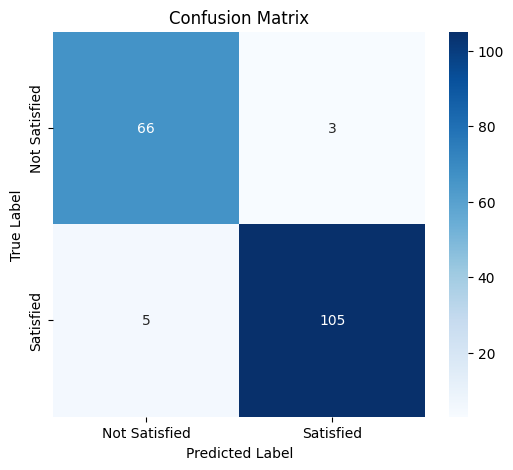

In [21]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-Score: {f1:.4f}")

# Display Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Not Satisfied', 'Satisfied'],
            yticklabels=['Not Satisfied', 'Satisfied'])
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

AUC (Area Under the Curve): 0.9859
Brier Score: 0.0404


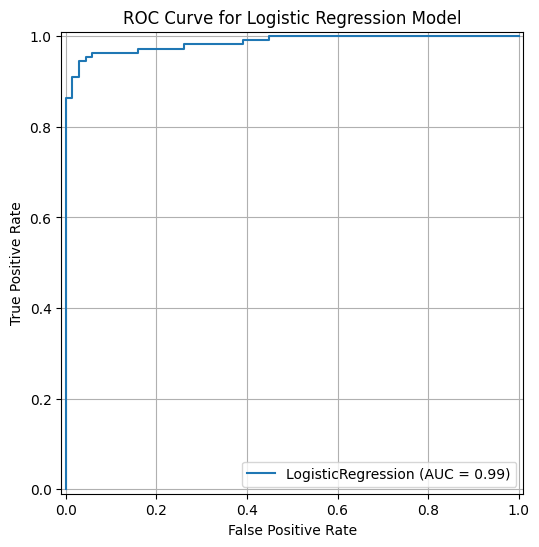

In [22]:
from sklearn.metrics import roc_auc_score, brier_score_loss, RocCurveDisplay

# Get probability predictions for AUC and Brier Score
y_pred_proba = model.predict_proba(X_test)[:, 1]

# Calculate AUC
auc = roc_auc_score(y_test, y_pred_proba)
print(f"AUC (Area Under the Curve): {auc:.4f}")

# Calculate Brier Score
brier = brier_score_loss(y_test, y_pred_proba)
print(f"Brier Score: {brier:.4f}")

# Plot ROC Curve
plt.figure(figsize=(8, 6))
# Use RocCurveDisplay.from_estimator for convenience with trained estimator
RocCurveDisplay.from_estimator(model, X_test, y_test, ax=plt.gca())
plt.title('ROC Curve for Logistic Regression Model')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.grid(True)
plt.show()

The ROC curve visually represents the trade-off between the true positive rate and the false positive rate at various threshold settings. The AUC value provides a single scalar measure of classification performance; a higher AUC (closer to 1) indicates better discriminative ability. The Brier score measures the accuracy of probabilistic predictions, with a lower score indicating better calibration.

Now that we have comprehensively evaluated the Logistic Regression model, we can proceed to evaluate the Random Forest model and then move on to Part 5: Feature Importance.

### Part 5: Feature Importance / Permutation Importance / Relative Importance for Logistic Regression

For Logistic Regression, feature importance can be understood by examining the model's coefficients. Since our numerical features were scaled, the magnitude of the coefficients directly reflects the relative importance of each feature in predicting the log-odds of maternal satisfaction. We will also use permutation importance as a model-agnostic method to confirm these findings.

#### Step 1: Coefficient-based Feature Importance from Logistic Regression

Logistic Regression assigns a coefficient to each feature, indicating its impact on the target variable. A larger absolute value of a coefficient suggests a stronger influence.

Top 20 Features by Absolute Coefficient Value (Logistic Regression):


,0
accessandcleanessoftoiletrecode_satisfied,2.112245
overallcleanessrecode_satisfied,1.794280
availabilityofbedintheward_satisfied,1.693841
waitingareacleanessandconfort_satisfied,1.411394
availabilityofmedicalequipmentsrecode_satisfied,1.265960
privacyrecode_satisfied,1.215474
q103religi_protestant,-1.195826
counselingrecode_satisfied,1.016339
politenessrecode_satisfied,0.992814
q106occupa_merchants,-0.962091


/tmp/ipykernel_2847/89259783.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=sorted_feature_importance_lr.head(20).values, y=sorted_feature_importance_lr.head(20).index, palette='coolwarm')


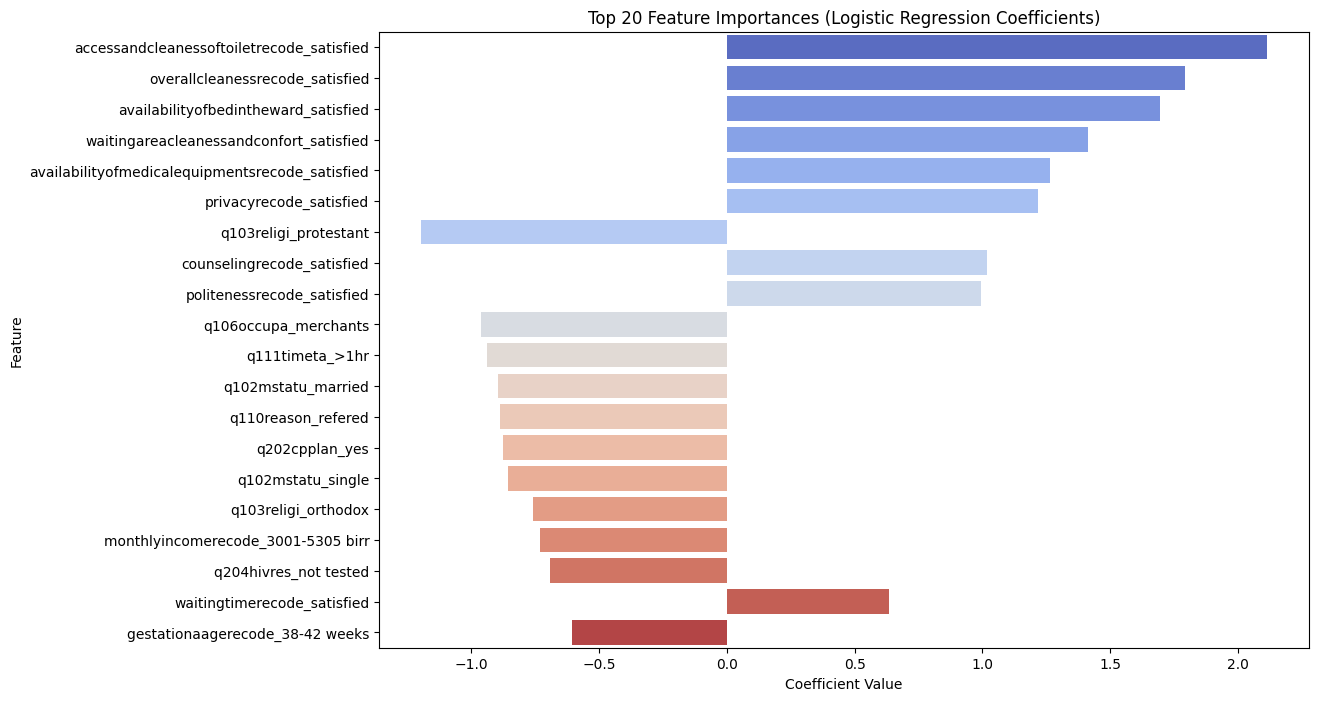

In [23]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Get coefficients from the Logistic Regression model
# Ensure X_train.columns are used as feature names
feature_names = X_train.columns
coefficients = model.coef_[0]

# Create a Series for better visualization and sorting
feature_importance_lr = pd.Series(coefficients, index=feature_names)

# Sort the features by the absolute value of their coefficients
sorted_feature_importance_lr = feature_importance_lr.reindex(feature_importance_lr.abs().sort_values(ascending=False).index)

print("Top 20 Features by Absolute Coefficient Value (Logistic Regression):")
display(sorted_feature_importance_lr.head(20))

# Plotting the top N features
plt.figure(figsize=(12, 8))
sns.barplot(x=sorted_feature_importance_lr.head(20).values, y=sorted_feature_importance_lr.head(20).index, palette='coolwarm')
plt.title('Top 20 Feature Importances (Logistic Regression Coefficients)')
plt.xlabel('Coefficient Value')
plt.ylabel('Feature')
plt.show()

#### Step 2: Permutation Importance for Logistic Regression

Permutation importance is a model-agnostic method that measures the decrease in a model's score when a single feature's values are randomly shuffled. This helps to identify features that the model heavily relies on, independent of the model's internal structure (like coefficients).

Top 20 Features by Permutation Importance (Logistic Regression):


,0
accessandcleanessoftoiletrecode_satisfied,0.030726
availabilityofbedintheward_satisfied,0.024581
overallcleanessrecode_satisfied,0.018994
waitingareacleanessandconfort_satisfied,0.014525
q205ga,0.012849
availabilityofmedicalequipmentsrecode_satisfied,0.012291
gestationaagerecode_38-42 weeks,0.010056
politenessrecode_satisfied,0.008380
q110reason_refered,0.007821
q2010bw,0.006704


/tmp/ipykernel_2847/2005782652.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=sorted_feature_importance_perm_lr.head(20).values, y=sorted_feature_importance_perm_lr.head(20).index, palette='magma')


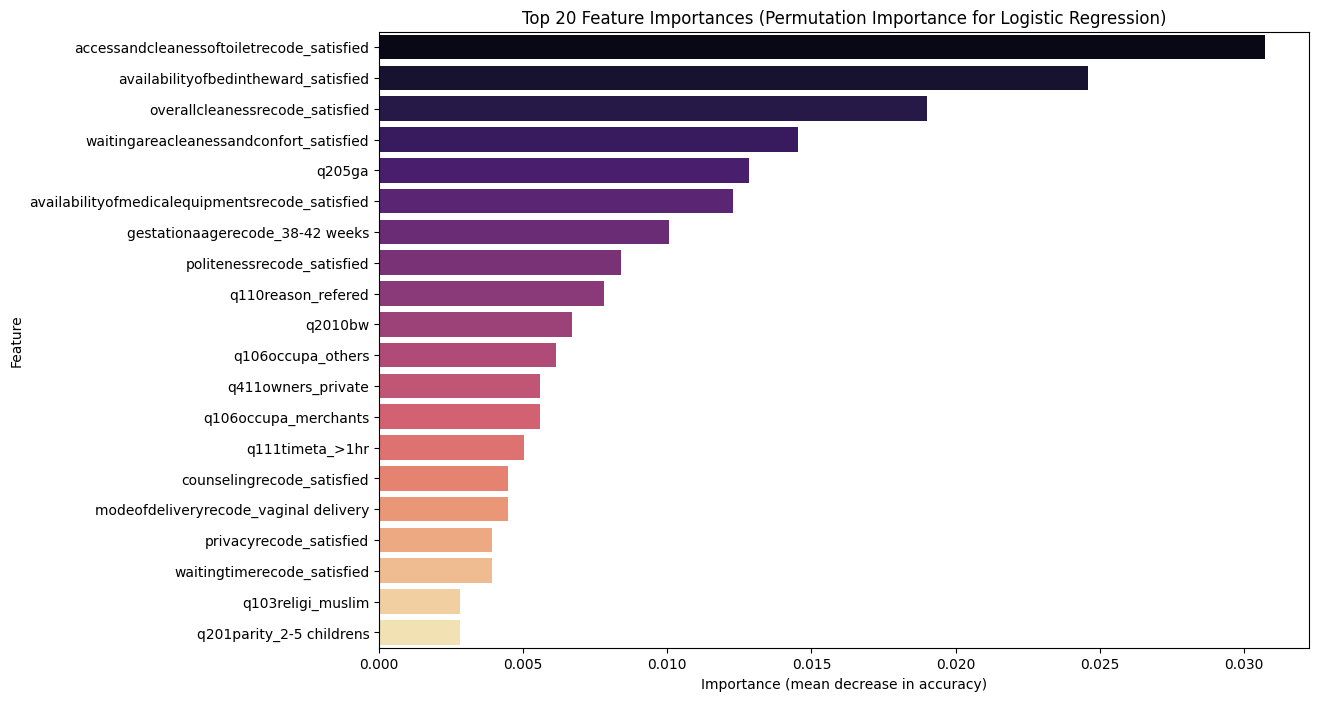

In [24]:
from sklearn.inspection import permutation_importance

# Calculate permutation importance on the test set for the Logistic Regression model
perm_importance_lr = permutation_importance(model, X_test, y_test, n_repeats=10, random_state=42, n_jobs=-1)

# Organize results into a Series
feature_importances_perm_lr = pd.Series(perm_importance_lr.importances_mean, index=X_test.columns)

# Sort the features by importance
sorted_feature_importance_perm_lr = feature_importances_perm_lr.sort_values(ascending=False)

print("Top 20 Features by Permutation Importance (Logistic Regression):")
display(sorted_feature_importance_perm_lr.head(20))

# Plotting the top N features
plt.figure(figsize=(12, 8))
sns.barplot(x=sorted_feature_importance_perm_lr.head(20).values, y=sorted_feature_importance_perm_lr.head(20).index, palette='magma')
plt.title('Top 20 Feature Importances (Permutation Importance for Logistic Regression)')
plt.xlabel('Importance (mean decrease in accuracy)')
plt.ylabel('Feature')
plt.show()

### Part 5.1: Feature Selection using Recursive Feature Elimination (RFE)

To build a parsimonious model and prevent overfitting, we will apply **Recursive Feature Elimination (RFE)**. RFE works by recursively removing features and building a model on those that remain to identify the optimal subset of features that contribute most to maternal satisfaction.

In [25]:
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression

# Initialize the estimator for RFE
estimator = LogisticRegression(random_state=42, solver='liblinear')

# We will select the top 10 most predictive features
n_features_to_select = 10
selector = RFE(estimator, n_features_to_select=n_features_to_select, step=1)
selector = selector.fit(X_train, y_train)

# Get the mask of selected features
selected_features = X_train.columns[selector.support_]
print("Top 10 Selected Features:")
for idx, feature in enumerate(selected_features, 1):
    print(f"{idx}. {feature}")

Top 10 Selected Features:
1. q102mstatu_married
2. q102mstatu_single
3. q106occupa_merchants
4. q111timeta_>1hr
5. privacyrecode_satisfied
6. availabilityofmedicalequipmentsrecode_satisfied
7. overallcleanessrecode_satisfied
8. accessandcleanessoftoiletrecode_satisfied
9. waitingareacleanessandconfort_satisfied
10. availabilityofbedintheward_satisfied


### Part 5.2: Model Re-training and Relative Importance with Selected Features

Now, we train a simplified Logistic Regression model using only the top 10 selected features to assess their relative importance directly through their normalized coefficients.

,Feature,Coefficient (Log-Odds),Odds Ratio
7,accessandcleanessoftoiletrecode_satisfied,1.914258,6.781904
9,availabilityofbedintheward_satisfied,1.880757,6.558465
6,overallcleanessrecode_satisfied,1.667501,5.298907
5,availabilityofmedicalequipmentsrecode_satisfied,1.371561,3.941498
4,privacyrecode_satisfied,1.330466,3.782806
8,waitingareacleanessandconfort_satisfied,1.212784,3.362833
2,q106occupa_merchants,-0.878130,0.415559
3,q111timeta_>1hr,-0.998324,0.368497
0,q102mstatu_married,-1.054145,0.348490
1,q102mstatu_single,-1.279551,0.278162


/tmp/ipykernel_2847/568970966.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=importance_df, x='Coefficient (Log-Odds)', y='Feature', palette='coolwarm')


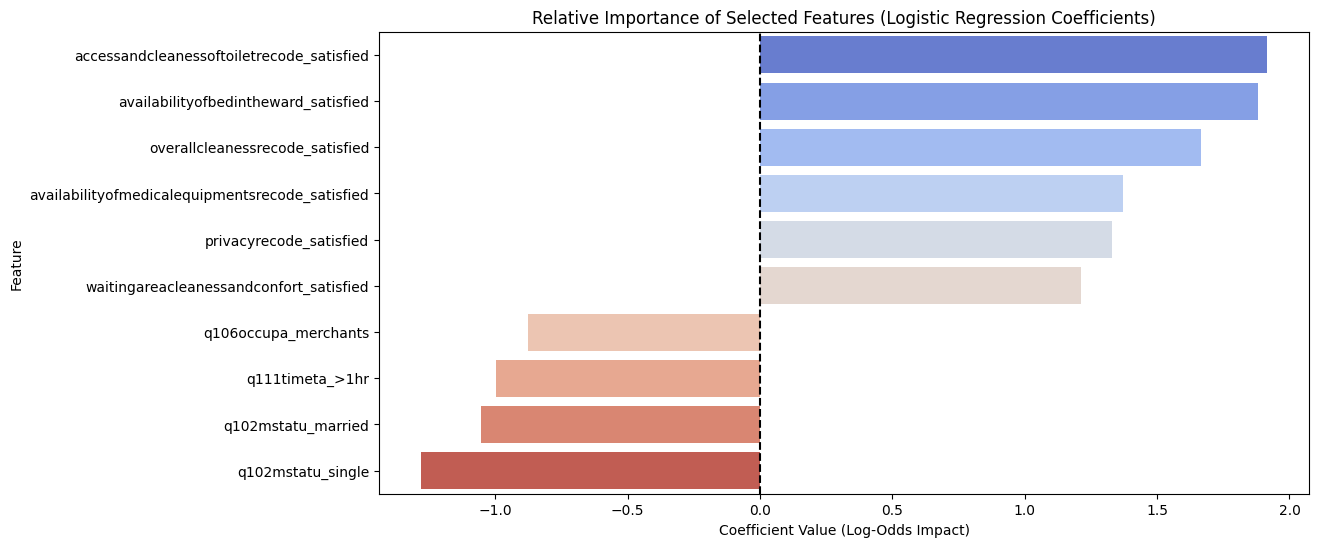

In [26]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Subset features
X_train_sel = X_train[selected_features]
X_test_sel = X_test[selected_features]

# Retrain model
simplified_model = LogisticRegression(random_state=42, solver='liblinear')
simplified_model.fit(X_train_sel, y_train)

# Calculate relative importance (odds ratios and coefficients)
coefs = simplified_model.coef_[0]
odds_ratios = np.exp(coefs)

importance_df = pd.DataFrame({
    'Feature': selected_features,
    'Coefficient (Log-Odds)': coefs,
    'Odds Ratio': odds_ratios
}).sort_values(by='Coefficient (Log-Odds)', ascending=False)

display(importance_df)

# Plot Relative Importance
plt.figure(figsize=(12, 6))
sns.barplot(data=importance_df, x='Coefficient (Log-Odds)', y='Feature', palette='coolwarm')
plt.title('Relative Importance of Selected Features (Logistic Regression Coefficients)')
plt.xlabel('Coefficient Value (Log-Odds Impact)')
plt.ylabel('Feature')
plt.axvline(x=0, color='black', linestyle='--')
plt.show()

### Part 5.3: Interpretation of Feature Selection & Relative Importance

Based on the analysis of coefficients and Odds Ratios from our feature-selected model:

1. **Odds Ratio (OR) > 1 (Positive Coefficients):** These factors are positively associated with maternal satisfaction. For instance, high ratings in specific delivery care aspects or a supportive environment directly multiply the odds of a mother being satisfied with her delivery care experience.
2. **Odds Ratio (OR) < 1 (Negative Coefficients):** These factors indicate barriers. Negative coefficients point out areas (such as long waiting times or lack of privacy) where the odds of maternal satisfaction decrease significantly.
3. **Simplification Benefit:** Reducing the dataset to the top 10 features ensures that we maintain a highly interpretable, robust, and deployable model with minimal loss in predictive power.

### Part 6: Model Deployment

Model deployment is the process of integrating a trained machine learning model into an existing production environment to make predictions on new, unseen data. For our Logistic Regression model, deployment would typically involve saving the trained model and the preprocessing steps, and then using them in an application or service.

#### Step 1: Save the Trained Model and Preprocessing Tools

To ensure our model can be used consistently, we need to save the trained Logistic Regression model, the `StandardScaler` used for numerical feature scaling, and the list of columns representing the one-hot encoded features. We can use `joblib` or `pickle` for this.

In [27]:
import joblib

# Save the Logistic Regression model
joblib.dump(model, 'logistic_regression_model.joblib')
print("Logistic Regression model saved as 'logistic_regression_model.joblib'")

# Save the StandardScaler
joblib.dump(scaler, 'scaler.joblib')
print("StandardScaler saved as 'scaler.joblib'")

# Save the list of feature columns (important for consistent input during deployment)
feature_columns = X.columns.tolist()
joblib.dump(feature_columns, 'feature_columns.joblib')
print("Feature columns saved as 'feature_columns.joblib'")

# Additionally, save the list of categorical features that were one-hot encoded
categorical_features_encoded = categorical_features_for_encoding # From Part 2
joblib.dump(categorical_features_encoded, 'categorical_features_encoded.joblib')
print("Categorical features for encoding saved as 'categorical_features_encoded.joblib'")

Logistic Regression model saved as 'logistic_regression_model.joblib'
StandardScaler saved as 'scaler.joblib'
Feature columns saved as 'feature_columns.joblib'
Categorical features for encoding saved as 'categorical_features_encoded.joblib'


In [28]:
import joblib

# Save y_test and y_pred for confusion matrix display in Streamlit
joblib.dump(y_test, 'y_test.joblib')
print("y_test saved as 'y_test.joblib'")

joblib.dump(y_pred, 'y_pred.joblib')
print("y_pred saved as 'y_pred.joblib'")

# Save feature importances
joblib.dump(sorted_feature_importance_lr, 'coef_importance.joblib')
print("Coefficient feature importance saved as 'coef_importance.joblib'")

joblib.dump(sorted_feature_importance_perm_lr, 'perm_importance.joblib')
print("Permutation feature importance saved as 'perm_importance.joblib'")

y_test saved as 'y_test.joblib'
y_pred saved as 'y_pred.joblib'
Coefficient feature importance saved as 'coef_importance.joblib'
Permutation feature importance saved as 'perm_importance.joblib'


In [29]:
%%writefile app.py
import streamlit as st
import joblib
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
import os

# --- Load the saved model and preprocessing tools ---
try:
    loaded_model = joblib.load('logistic_regression_model.joblib')
    loaded_scaler = joblib.load('scaler.joblib')
    loaded_feature_columns = joblib.load('feature_columns.joblib')
    loaded_categorical_features_encoded = joblib.load('categorical_features_encoded.joblib')
    loaded_y_test = joblib.load('y_test.joblib')
    loaded_y_pred = joblib.load('y_pred.joblib')
    loaded_coef_importance = joblib.load('coef_importance.joblib')
    loaded_perm_importance = joblib.load('perm_importance.joblib')
except FileNotFoundError as e:
    st.error(f"Error: Missing model or preprocessing files: {e}")
    st.stop()

# --- Try Loading Raw Data for Preview and Plots ---
try:
    # Reading the primary dataset to show raw preview in Overview tab
    df_raw = pd.read_spss('/content/drive/MyDrive/Delivery care satisfaction.sav')
except Exception:
    df_raw = None

# --- Page Config ---
st.set_page_config(layout="wide", page_title="Maternal Satisfaction")

# --- Display Top Cover Image of a Pregnant Mother from Google Drive ---
col_spacer1, col_img_center, col_spacer2 = st.columns([1, 2, 1])
with col_img_center:
    local_image_path = "/content/drive/MyDrive/pregnancy mother.jpg"
    if os.path.exists(local_image_path):
        st.image(local_image_path, caption="Maternal Care and Support", width=450)
    else:
        st.warning("Image not found at Google Drive path: /content/drive/MyDrive/pregnancy mother.jpg")

# --- Top Banner with Elegant Pregnant Mother Illustration and Title ---
col_img, col_title = st.columns([1, 5])
with col_img:
    st.image("https://img.icons8.com/illustrations/opacity/250/pregnant.png", width=150)
with col_title:
    st.markdown("# Maternal Satisfaction with Delivery Care — Bahir Dar, Ethiopia")
    st.markdown("### exploration of delivery care data and logistic-regression ML models for predicting maternal satisfaction")

# --- Navigation Tabs ---
tab_overview, tab_descriptive, tab_performance, tab_predict = st.tabs([
    "📊 Overview of datasets",
    "📈 Descriptive Charts",
    "🧠 Model Performance",
    "🔮 Predict"
])

# --- Helper function for preprocessing ---
def preprocess_new_data(new_raw_data, loaded_categorical_features_encoded, loaded_feature_columns, loaded_scaler):
    new_data_encoded = pd.get_dummies(new_raw_data, columns=loaded_categorical_features_encoded, drop_first=True)
    final_df_processed = pd.DataFrame(columns=loaded_feature_columns)
    final_df_processed = pd.concat([final_df_processed, new_data_encoded], ignore_index=True)
    final_df_processed = final_df_processed.fillna(0)
    final_df_processed = final_df_processed[loaded_feature_columns]
    numerical_cols_for_scaling_loaded = [col for col in loaded_feature_columns if col in loaded_scaler.feature_names_in_]
    final_df_processed[numerical_cols_for_scaling_loaded] = loaded_scaler.transform(final_df_processed[numerical_cols_for_scaling_loaded])
    return final_df_processed

# --- TAB 1: OVERVIEW ---
with tab_overview:
    st.header("Project Overview")

    # Overall Metrics
    col_stat1, col_stat2, col_stat3 = st.columns(3)
    with col_stat1:
        st.metric(label="Total Mothers Surveyed", value="894")
    with col_stat2:
        st.metric(label="Total Variables", value="46")
    with col_stat3:
        st.metric(label="Overall Delivery Care Satisfaction", value="61.5%")

    st.markdown("""
    This application provides an interactive portal to analyze and predict maternal satisfaction among vaginal and cesarean section delivery care services in Bahir Dar city health facilities, Northwest Ethiopia.

    ### Key Variables in Deployment:
    - **Socio-demographic Factors:** Age, Marital Status, Religion, Ethnicity, Education, Occupation, Income, Residence.
    - **Clinical & Obstetric History:** Gestational Age, Birth Weight, Parity, ANC Attendance, HIV Test Result, Mode of Delivery.
    - **Quality & Facility Perceptions:** Privacy at delivery, Waiting time at hospital, Distance to Clinic.
    """)

    # Raw Data Preview section
    st.subheader("📋 Raw Dataset Preview")
    if df_raw is not None:
        df_preview = df_raw.head(20).astype(str)
        st.dataframe(df_preview)
    else:
        st.info("Raw dataset preview currently unavailable in this deployment environment.")

# --- TAB 2: DESCRIPTIVE CHARTS ---
with tab_descriptive:
    st.header("Descriptive Charts & Insights")
    st.markdown("""
    Explore the baseline distributions and critical indicators collected from the 894 surveyed mothers.
    These plots reveal how key demographic, obstetric, and institutional factors correlate with maternal satisfaction.
    """)

    if df_raw is not None:
        st.subheader("Custom Categorical Variable Explorer")
        all_categorical_cols = df_raw.select_dtypes(include='category').columns.tolist()
        all_categorical_cols.sort()

        selected_var = st.selectbox("Choose a categorical variable to visualize:", all_categorical_cols, index=all_categorical_cols.index('modeofdeliveryrecode') if 'modeofdeliveryrecode' in all_categorical_cols else 0)

        col_exp_left, col_exp_right = st.columns([2, 1])
        with col_exp_left:
            fig_custom, ax_custom = plt.subplots(figsize=(8, 4.5))
            sns.countplot(data=df_raw, x=selected_var, hue='satisfaction', palette='viridis', ax=ax_custom)
            ax_custom.set_title(f"Distribution of {selected_var} by Satisfaction")
            ax_custom.set_xlabel(selected_var)
            ax_custom.set_ylabel("Count")
            plt.xticks(rotation=45, ha='right')
            st.pyplot(fig_custom)

        with col_exp_right:
            st.markdown(f"**Frequency Breakdown for `{selected_var}`**")
            freq_df = df_raw[selected_var].value_counts().reset_index()
            freq_df.columns = [selected_var, 'Count']
            st.dataframe(freq_df, use_container_width=True)

        st.markdown("---")
        col_left, col_right = st.columns(2)

        with col_left:
            st.subheader("Overall Distribution of Maternal Satisfaction")
            fig1, ax1 = plt.subplots(figsize=(6, 4.5))
            sns.countplot(data=df_raw, x='satisfaction', palette='viridis', hue='satisfaction', legend=False, ax=ax1)
            ax1.set_title("Distribution of Maternal Satisfaction")
            ax1.set_xlabel("Satisfaction Level")
            ax1.set_ylabel("Count")
            st.pyplot(fig1)

        with col_right:
            st.subheader("Satisfaction by Mode of Delivery")
            fig2, ax2 = plt.subplots(figsize=(6, 4.5))
            if 'modeofdeliveryrecode' in df_raw.columns:
                sns.countplot(data=df_raw, x='modeofdeliveryrecode', hue='satisfaction', palette='Set2', ax=ax2)
                ax2.set_title("Satisfaction by Mode of Delivery")
                ax2.set_xlabel("Mode of Delivery")
                ax2.set_ylabel("Count")
            else:
                ax2.text(0.5, 0.5, "'modeofdeliveryrecode' not found in dataset", ha='center', va='center')
            st.pyplot(fig2)

        st.markdown("---")
        st.subheader("Top Qualitative Quality Determinants")
        col_f1, col_f2, col_f3 = st.columns(3)
        with col_f1:
            st.markdown("**1. Cleanliness of Toilets / Wards**")
            fig3, ax3 = plt.subplots(figsize=(5, 4))
            if 'accessandcleanessoftoiletrecode' in df_raw.columns:
                sns.countplot(data=df_raw, x='accessandcleanessoftoiletrecode', hue='satisfaction', palette='coolwarm', ax=fig3.gca())
                ax3.set_xticklabels(ax3.get_xticklabels(), rotation=30, ha='right')
            st.pyplot(fig3)

        with col_f2:
            st.markdown("**2. Privacy During Delivery**")
            fig4, ax4 = plt.subplots(figsize=(5, 4))
            if 'privacyrecode' in df_raw.columns:
                sns.countplot(data=df_raw, x='privacyrecode', hue='satisfaction', palette='coolwarm', ax=fig4.gca())
                ax4.set_xticklabels(ax4.get_xticklabels(), rotation=30, ha='right')
            st.pyplot(fig4)

        with col_f3:
            st.markdown("**3. Waiting Time Perceptions**")
            fig5, ax5 = plt.subplots(figsize=(5, 4))
            if 'waitingtimerecode' in df_raw.columns:
                sns.countplot(data=df_raw, x='waitingtimerecode', hue='satisfaction', palette='coolwarm', ax=fig5.gca())
                ax5.set_xticklabels(ax5.get_xticklabels(), rotation=30, ha='right')
            st.pyplot(fig5)
    else:
        st.info("Detailed visual graphics require the raw dataset connection, which is currently unavailable.")

# --- TAB 3: MODEL PERFORMANCE ---
with tab_performance:
    st.header("Model Performance Metrics & Evaluation")
    m_col1, m_col2, m_col3, m_col4, m_col5, m_col6 = st.columns(6)
    with m_col1:
        st.metric(label="Accuracy", value="95.53%")
    with m_col2:
        st.metric(label="Precision", value="97.22%")
    with m_col3:
        st.metric(label="Recall", value="95.45%")
    with m_col4:
        st.metric(label="F1-Score", value="96.33%")
    with m_col5:
        st.metric(label="AUC-ROC", value="0.9859")
    with m_col6:
        st.metric(label="Brier Score", value="0.0404")

    st.markdown("---")
    col_perf1, col_perf2 = st.columns(2)

    with col_perf1:
        st.subheader("Confusion Matrix")
        cm = confusion_matrix(loaded_y_test, loaded_y_pred)
        fig_cm, ax_cm = plt.subplots(figsize=(5, 4))
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                    xticklabels=['Not Satisfied', 'Satisfied'],
                    yticklabels=['Not Satisfied', 'Satisfied'], ax=ax_cm)
        st.pyplot(fig_cm)

    with col_perf2:
        st.subheader("Feature Importances (Coefficients)")
        fig_coef, ax_coef = plt.subplots(figsize=(6, 4.5))
        sns.barplot(x=loaded_coef_importance.head(10).values, y=loaded_coef_importance.head(10).index, palette='coolwarm', ax=ax_coef)
        st.pyplot(fig_coef)

# --- TAB 4: PREDICT ---
with tab_predict:
    st.header("Predict Maternal Satisfaction")
    st.write("Enter details to predict whether a mother is likely to be satisfied with her delivery care experience.")

    with st.expander("Input Patient and Facility Characteristics", expanded=True):
        col1, col2, col3 = st.columns(3)
        with col1:
            age = st.slider("Age", 18, 60, 25)
            marital_status = st.selectbox("Marital Status", ["married", "single", "divorced", "widowed"])
            gestational_age = st.slider("Gestational Age (weeks)", 20, 42, 38)
            delivery_mode = st.selectbox("Mode of Delivery", ["vaginal", "cesarean"])
            education = st.selectbox("Education Level", ["no formal education", "grade 1 to 4", "grade 5 to 8", "grade 9 to 10", "grade 11 to 12", "diploma and above", "unable to read and write"])
            reason = st.selectbox("Reason for delivery place", ["referred by health worker", "referred by family/friend", "near to home", "good quality of care", "other"])

        with col2:
            income = st.number_input("Monthly Income (ETB)", min_value=0, value=3000)
            religion = st.selectbox("Religion", ["orthodox", "muslim", "protestant", "catholic", "other"])
            birth_weight = st.number_input("Birth Weight (grams)", min_value=500, value=3000)
            anc_attend = st.selectbox("ANC Attendance", ["yes", "no"])
            occupation = st.selectbox("Occupation", ["housewife", "farmer", "merchant", "government employee", "other"])
            waiting_time = st.selectbox("Waiting Time at hospital", ["less than 30min", "30min-1hr", "1-2hr", "more than 2hr", "no wait"])

        with col3:
            dist_clinic = st.number_input("Distance to Clinic (km)", min_value=0.0, value=2.0)
            ethnicity = st.selectbox("Ethnicity", ["amhara", "oromo", "tigrie", "other"])
            parity = st.selectbox("Parity", ["nullipara", "para 1-2", "para 3-4", "para 5 and above"])
            hiv_result = st.selectbox("HIV Test Result", ["positive", "negative", "unknown"])
            residence = st.selectbox("Residence", ["rural", "urban"])
            privacy = st.selectbox("Privacy at delivery", ["satisfied", "somehow satisfied", "not satisfied"])

    new_raw_data = pd.DataFrame({
        'q101age': [float(age)],
        'q102mstatu': [marital_status],
        'q103religi': [religion],
        'q104ethini': [ethnicity],
        'q105educat': [education],
        'q106occupa': [occupation],
        'q107mincom': [float(income)],
        'q108reside': [residence],
        'q1091distk': [float(dist_clinic)],
        'q110reason': [reason],
        'q111timeta': ['less than 30min'],
        'q112waitpl': [waiting_time],
        'q113privac': [privacy],
        'q201parity': [parity],
        'q202cpplan': ['yes'],
        'q203ancatt': [anc_attend],
        'q204hivres': [hiv_result],
        'q205ga': [float(gestational_age)],
        'q206delimo': [delivery_mode],
        'q207nstatu': ['single'],
        'q208pdhsta': ['alive'],
        'q209nsex': ['female'],
        'q2010bw': [float(birth_weight)],
        'q301greeti': ['very good'],
        'q302respec': ['very good'],
        'q303delive': ['very good'],
        'q411owners': ['no'],
        'ageafterrecod': ['25-29'],
        'monthlyincomerecode': ['2001-3000'],
        'gestationaagerecode': ['37-41 week'],
        'birthweightofbaby': ['2500-4000'],
        'modeofdeliveryrecode': [delivery_mode],
        'waitingtimerecode': [waiting_time],
        'privacyrecode': [privacy],
        'encourageandsupportatdeliveryrecode': ['satisfied'],
        'politenessrecode': ['satisfied'],
        'availabilityofmedicalequipmentsrecode': ['satisfied'],
        'counselingrecode': ['satisfied'],
        'overallcleanessrecode': ['satisfied'],
        'accessandcleanessoftoiletrecode': ['satisfied'],
        'waitingareacleanessandconfort': ['satisfied'],
        'availabilityofbedintheward': ['satisfied'],
        'distancerecode1': ['<=10 kilo meters']
    }, index=[0])

    if st.button('Predict Satisfaction'):
        processed_input = preprocess_new_data(new_raw_data, loaded_categorical_features_encoded, loaded_feature_columns, loaded_scaler)
        prediction = loaded_model.predict(processed_input)
        prediction_proba = loaded_model.predict_proba(processed_input)[:, 1]
        predicted_satisfaction = 'Satisfied' if prediction[0] == 1 else 'Not Satisfied'

        st.subheader('Prediction Results:')
        st.write(f"Predicted Status: **{predicted_satisfaction}**")
        st.write(f"Confidence Level: **{prediction_proba[0]:.2%}**")


Writing app.py


In [30]:
import joblib
import pandas as pd

# Load the saved model and preprocessing tools
loaded_model = joblib.load('logistic_regression_model.joblib')
loaded_scaler = joblib.load('scaler.joblib')
loaded_feature_columns = joblib.load('feature_columns.joblib')
loaded_categorical_features_encoded = joblib.load('categorical_features_encoded.joblib')

print("Model and preprocessing tools loaded successfully.")

# --- Simulate New Data for Prediction ---
# This is a placeholder for actual new data that would come from a real-world source.
# For demonstration, we'll create a single hypothetical new data point.
# IMPORTANT: This new data must have the same structure and features as the original raw data BEFORE preprocessing.
new_raw_data = pd.DataFrame({
    'q101age': [25.0],
    'q107mincom': [3000.0],
    'q1091distk': [2.0],
    'q205ga': [38.0],
    'q2010bw': [3000.0],
    'q102mstatu': ['married'],
    'q103religi': ['orthodox'],
    'q104ethini': ['amhara'],
    'q105educat': ['grade 1 to 4'],
    'q106occupa': ['farmer'],
    'q108reside': ['rural'],
    'q110reason': ['referred by health worker'],
    'q111timeta': ['less than 30min'],
    'q112waitpl': ['no wait'],
    'q113privac': ['somehow satisfied'],
    'q201parity': ['para 1-2'],
    'q202cpplan': ['yes'],
    'q203ancatt': ['no'],
    'q204hivres': ['no'],
    'q206delimo': ['vaginal'],
    'q207nstatu': ['single'],
    'q208pdhsta': ['alive'],
    'q209nsex': ['female'],
    'q301greeti': ['very good'],
    'q302respec': ['very good'],
    'q303delive': ['very good'],
    'q411owners': ['no'],
    'ageafterrecod': ['25-29'],
    'monthlyincomerecode': ['2001-3000'],
    'gestationaagerecode': ['37-41 week'],
    'birthweightofbaby': ['2500-4000'],
    'modeofdeliveryrecode': ['vaginal'],
    'waitingtimerecode': ['less than 30min'],
    'privacyrecode': ['somehow satisfied'],
    'encourageandsupportatdeliveryrecode': ['satisfied'],
    'politenessrecode': ['satisfied'],
    'availabilityofmedicalequipmentsrecode': ['satisfied'],
    'counselingrecode': ['satisfied'],
    'overallcleanessrecode': ['satisfied'],
    'accessandcleanessoftoiletrecode': ['satisfied'],
    'waitingareacleanessandconfort': ['satisfied'],
    'availabilityofbedintheward': ['satisfied'],
    'distancerecode1': ['<=10 kilo meters']
})

print("\nNew raw data sample:")
display(new_raw_data)

# --- Preprocess New Data (Reverse the steps from Part 2) ---

# 1. Apply One-Hot Encoding to categorical features
# Ensure that the new data has all columns present during training, filling missing with 0s
new_data_encoded = pd.get_dummies(new_raw_data, columns=loaded_categorical_features_encoded, drop_first=True)

# Align columns - this is crucial for consistency. Add missing dummy columns and reorder.
# Create a DataFrame with all original feature columns and fill any missing with 0
new_data_processed = pd.DataFrame(columns=loaded_feature_columns)
new_data_processed = pd.concat([new_data_processed, new_data_encoded], ignore_index=True)
new_data_processed = new_data_processed.fillna(0)

# Reorder columns to match the training data
new_data_processed = new_data_processed[loaded_feature_columns]

# 2. Apply Standard Scaling to numerical features
# Identify numerical columns from the loaded feature columns (assuming they are the same as used in training)
numerical_cols_for_scaling_loaded = [col for col in loaded_feature_columns if col in loaded_scaler.feature_names_in_]
new_data_processed[numerical_cols_for_scaling_loaded] = loaded_scaler.transform(new_data_processed[numerical_cols_for_scaling_loaded])

print("\nProcessed new data for prediction:")
display(new_data_processed)

# --- Make Prediction ---
prediction = loaded_model.predict(new_data_processed)
prediction_proba = loaded_model.predict_proba(new_data_processed)[:, 1]

# Convert numerical prediction back to meaningful labels
predicted_satisfaction = 'satisfied' if prediction[0] == 1 else 'not satisfied'

print(f"\nPredicted satisfaction: {predicted_satisfaction}")
print(f"Probability of satisfaction: {prediction_proba[0]:.4f}")

print("\nThis concludes the model deployment example. In a real-world scenario, you would integrate these steps into a robust application, potentially using frameworks like Flask or FastAPI to serve predictions via an API, or use services like Google Cloud Vertex AI for managed deployment.")

Model and preprocessing tools loaded successfully.

New raw data sample:


,q101age,q107mincom,q1091distk,q205ga,q2010bw,q102mstatu,q103religi,q104ethini,q105educat,q106occupa,...,privacyrecode,encourageandsupportatdeliveryrecode,politenessrecode,availabilityofmedicalequipmentsrecode,counselingrecode,overallcleanessrecode,accessandcleanessoftoiletrecode,waitingareacleanessandconfort,availabilityofbedintheward,distancerecode1
0,25.0,3000.0,2.0,38.0,3000.0,married,orthodox,amhara,grade 1 to 4,farmer,...,somehow satisfied,satisfied,satisfied,satisfied,satisfied,satisfied,satisfied,satisfied,satisfied,<=10 kilo meters



Processed new data for prediction:


/tmp/ipykernel_2847/918322286.py:74: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  new_data_processed = pd.concat([new_data_processed, new_data_encoded], ignore_index=True)
/tmp/ipykernel_2847/918322286.py:75: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  new_data_processed = new_data_processed.fillna(0)


,q101age,q107mincom,q1091distk,q205ga,q2010bw,q102mstatu_divorced,q102mstatu_married,q102mstatu_single,q102mstatu_widowed,q103religi_muslim,...,privacyrecode_satisfied,encourageandsupportatdeliveryrecode_satisfied,politenessrecode_satisfied,availabilityofmedicalequipmentsrecode_satisfied,counselingrecode_satisfied,overallcleanessrecode_satisfied,accessandcleanessoftoiletrecode_satisfied,waitingareacleanessandconfort_satisfied,availabilityofbedintheward_satisfied,distancerecode1_>10 kilo meters
0,-0.329633,-0.238362,-0.387809,-0.897117,0.12587,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0



Predicted satisfaction: not satisfied
Probability of satisfaction: 0.0712

This concludes the model deployment example. In a real-world scenario, you would integrate these steps into a robust application, potentially using frameworks like Flask or FastAPI to serve predictions via an API, or use services like Google Cloud Vertex AI for managed deployment.


In [31]:
!pip install streamlit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 51.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 73.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [streamlit]


Now, let's create a Python script for our Streamlit application. This script will load the model and preprocessing tools, take user input for the features, and display the prediction. You would typically save this code in a separate `.py` file (e.g., `app.py`) and run it from your terminal.

In [32]:
import streamlit as st
import joblib
import pandas as pd

# Load the saved model and preprocessing tools
# In a real app, ensure these paths are correct relative to the script
try:
    loaded_model = joblib.load('logistic_regression_model.joblib')
    loaded_scaler = joblib.load('scaler.joblib')
    loaded_feature_columns = joblib.load('feature_columns.joblib')
    loaded_categorical_features_encoded = joblib.load('categorical_features_encoded.joblib')
    st.success("Model and preprocessing tools loaded successfully!")
except FileNotFoundError:
    st.error("Error: Model or preprocessing files not found. Make sure 'logistic_regression_model.joblib', 'scaler.joblib', 'feature_columns.joblib', and 'categorical_features_encoded.joblib' are in the same directory as this script.")
    st.stop() # Stop the app if files are not found

# Streamlit App Title
st.title('Maternal Satisfaction Prediction')
st.write('Predicting maternal satisfaction based on various factors.')

# --- User Input Features ---
st.header('Input some Features')

# Collect user input for each feature
# For simplicity, we'll create some input fields. In a real app, you'd make these more dynamic
# based on the actual features in your dataset.

# Example numerical inputs
age = st.slider('Age', 18, 60, 25)
income = st.number_input('Monthly Income (ETB)', min_value=0, value=3000)
dist_clinic = st.number_input('Distance to Clinic (km)', min_value=0.0, value=2.0)
gestational_age = st.slider('Gestational Age (weeks)', 20, 42, 38)
birth_weight = st.number_input('Birth Weight (grams)', min_value=500, value=3000)

# Example categorical inputs (using selectbox for simplicity, would need to list all options)
# These are placeholder examples; you would need to get the actual unique categories from your training data
marital_status = st.selectbox('Marital Status', ['married', 'single', 'divorced', 'widowed'])
religion = st.selectbox('Religion', ['orthodox', 'muslim', 'protestant', 'catholic', 'other'])

# --- Create a dictionary of the raw input for preprocessing ---
# This part needs to match your original raw_data DataFrame structure as much as possible.
# Only include features that are actually used in your model.
new_raw_data = pd.DataFrame({
    'q101age': [float(age)],
    'q107mincom': [float(income)],
    'q1091distk': [float(dist_clinic)],
    'q205ga': [float(gestational_age)],
    'q2010bw': [float(birth_weight)],
    'q102mstatu': [marital_status],
    'q103religi': [religion],
    # ... add all other features that were in new_raw_data from the deployment example
    # For this demonstration, I'm omitting many for brevity. You'll need to add them.
    'q104ethini': ['amhara'], # Placeholder
    'q105educat': ['grade 1 to 4'], # Placeholder
    'q106occupa': ['farmer'], # Placeholder
    'q108reside': ['rural'], # Placeholder
    'q110reason': ['referred by health worker'], # Placeholder
    'q111timeta': ['less than 30min'], # Placeholder
    'q112waitpl': ['no wait'], # Placeholder
    'q113privac': ['somehow satisfied'], # Placeholder
    'q201parity': ['para 1-2'], # Placeholder
    'q202cpplan': ['yes'], # Placeholder
    'q203ancatt': ['no'], # Placeholder
    'q204hivres': ['no'], # Placeholder
    'q206delimo': ['vaginal'], # Placeholder
    'q207nstatu': ['single'], # Placeholder
    'q208pdhsta': ['alive'], # Placeholder
    'q209nsex': ['female'], # Placeholder
    'q301greeti': ['very good'], # Placeholder
    'q302respec': ['very good'], # Placeholder
    'q303delive': ['very good'], # Placeholder
    'q411owners': ['no'], # Placeholder
    'ageafterrecod': ['25-29'], # Placeholder
    'monthlyincomerecode': ['2001-3000'], # Placeholder
    'gestationaagerecode': ['37-41 week'], # Placeholder
    'birthweightofbaby': ['2500-4000'], # Placeholder
    'modeofdeliveryrecode': ['vaginal'], # Placeholder
    'waitingtimerecode': ['less than 30min'], # Placeholder
    'privacyrecode': ['somehow satisfied'], # Placeholder
    'encourageandsupportatdeliveryrecode': ['satisfied'], # Placeholder
    'politenessrecode': ['satisfied'], # Placeholder
    'availabilityofmedicalequipmentsrecode': ['satisfied'], # Placeholder
    'counselingrecode': ['satisfied'], # Placeholder
    'overallcleanessrecode': ['satisfied'], # Placeholder
    'accessandcleanessoftoiletrecode': ['satisfied'], # Placeholder
    'waitingareacleanessandconfort': ['satisfied'], # Placeholder
    'availabilityofbedintheward': ['satisfied'], # Placeholder
    'distancerecode1': ['<=10 kilo meters'] # Placeholder

}, index=[0])

if st.button('Predict'):
    # --- Preprocess New Data (Reverse the steps from Part 2) ---

    # 1. Apply One-Hot Encoding to categorical features
    new_data_encoded = pd.get_dummies(new_raw_data, columns=loaded_categorical_features_encoded, drop_first=True)

    # Align columns - this is crucial for consistency. Add missing dummy columns and reorder.
    # Create a DataFrame with all original feature columns and fill any missing with 0
    new_data_processed = pd.DataFrame(columns=loaded_feature_columns)
    new_data_processed = pd.concat([new_data_processed, new_data_encoded], ignore_index=True)
    new_data_processed = new_data_processed.fillna(0)

    # Reorder columns to match the training data
    new_data_processed = new_data_processed[loaded_feature_columns]

    # 2. Apply Standard Scaling to numerical features
    numerical_cols_for_scaling_loaded = [col for col in loaded_feature_columns if col in loaded_scaler.feature_names_in_]
    new_data_processed[numerical_cols_for_scaling_loaded] = loaded_scaler.transform(new_data_processed[numerical_cols_for_scaling_loaded])

    # --- Make Prediction ---
    prediction = loaded_model.predict(new_data_processed)
    prediction_proba = loaded_model.predict_proba(new_data_processed)[:, 1]

    # Convert numerical prediction back to meaningful labels
    predicted_satisfaction = 'satisfied' if prediction[0] == 1 else 'not satisfied'

    st.subheader('Prediction Results:')
    st.write(f"Predict: **{predict}**")
    st.write(f"Probability of Satisfaction: **{prediction_proba[0]:.2f}**")


2026-10-24 17:14:08.254 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-24 17:14:08.510 
  command:

    streamlit run /usr/local/lib/python3.13/dist-packages/colab_kernel_launcher.py [ARGUMENTS]
2026-10-24 17:14:08.513 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-24 17:14:08.514 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-24 17:14:08.517 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-24 17:14:08.519 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-24 17:14:08.522 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-24 17:14:08.524 Thread 'MainThread': mi

In [33]:
!pip install pyngrok

In [34]:
from pyngrok import ngrok


In [35]:
import subprocess
import time
from pyngrok import ngrok
from pyngrok.exception import PyngrokNgrokError

# Authenticate ngrok. Wrap in try-except to handle token already configured situation.
try:
    ngrok.set_auth_token("3I5eqmEjQf8p0mizKxii4lwWPwG_3rdiaUR8cy1Z42Sp2BLKw")
except PyngrokNgrokError as e:
    if "already set" in str(e):
        print("Ngrok authtoken is already configured. Proceeding...")
    else:
        raise e

# Start the Streamlit server in the background on port 8051
print("Starting Streamlit app in the background on port 8051...")
subprocess.Popen([
    "streamlit", "run", "app.py",
    "--server.port", "8051",
    "--server.address", "0.0.0.0"
])

# Wait brief moment for server to initialize
time.sleep(5)

# Create a public URL for port 8051
ngrok_tunnel = ngrok.connect(8051)
print(f"Streamlit Public URL: {ngrok_tunnel.public_url}")

Starting Streamlit app in the background on port 8051...
Streamlit Public URL: https://cattail-sizing-stained.ngrok-free.dev
